# Spektralstatistik und Quantenchaos

Das Notebook diagonalisiert die Mixed-Field-Ising-Kette exakt (bis 14 Qubits, getrennt nach Symmetriesektoren) und vergleicht die Statistik ihrer Energieniveaus mit der Zufallsmatrixtheorie: Verhältnisse benachbarter Abstände, Abstandsverteilung nach dem Entfalten, Zahlenvarianz auf langen Skalen, den Übergang von integrabel zu chaotisch in Abhängigkeit vom Längsfeld und den spektralen Formfaktor eines Ensembles mit schwacher Unordnung.

Woran erkennt man allein an den Energieniveaus eines Hamiltonoperators, ob ein Quantensystem chaotisch oder integrabel ist?

#### **Hintergrund**

In den 1950er-Jahren waren die Spektren schwerer Atomkerne zu kompliziert, um sie Niveau für Niveau zu berechnen. Wigner schlug vor, nur ihre Statistik zu beschreiben, und zwar mit den Eigenwerten zufälliger Matrizen. Das funktionierte erstaunlich gut: Benachbarte Niveaus stoßen sich ab, große Lücken und dichte Haufen sind selten. Bohigas, Giannoni und Schmit vermuteten 1984, dass das für jedes Quantensystem gilt, dessen klassischer Grenzfall chaotisch ist, während integrable Systeme unkorrelierte Niveaus haben wie zufällig hingestreute Punkte (Berry und Tabor 1977). Damit wurde die Niveaustatistik zum Standardtest für Quantenchaos, auch für Vielteilchensysteme ohne klassischen Grenzfall.

Der Test braucht keine Zeitentwicklung, nur das Spektrum: Er ist das statische Gegenstück zu den OTOCs und zum Operatorwachstum in [Quantum Chaos and Scrambling](https://github.com/deltorobarba/science/blob/main/quantum/quantumchaos.ipynb). Man findet dieselbe Statistik in Atomkernen, Quantenpunkten, Mikrowellen-Billards und Spinketten, in den Energieniveaus von Modellen Schwarzer Löcher (SYK-Modell) und in den Spektren supraleitender Qubit-Ketten, an denen man den Übergang zur Lokalisierung gemessen hat. Der spektrale Formfaktor verbindet Spektrum und Dynamik: Er ist eine Zeitfunktion, deren Form allein von den Korrelationen der Niveaus abhängt.

Bevor man die Statistik misst, muss man zwei Dinge erledigen: das Spektrum nach seinen Symmetrien zerlegen und die schwankende Zustandsdichte herausrechnen (Entfalten). Beides zeigt das Notebook an der Ising-Kette aus [Quantum Chaos and Scrambling](https://github.com/deltorobarba/science/blob/main/quantum/quantumchaos.ipynb), die bei $h_z = 0$ integrabel und bei $h_z = 0.5$ chaotisch ist.

Landkarte:

- **Vorbereitung**
  - Symmetrien zuerst (Exp. 1): Das ganze Spektrum der chaotischen Kette gibt $\langle r\rangle = 0.43$, näher an unkorrelierten Niveaus (0.39) als an Zufallsmatrizen; jeder Spiegelsektor für sich gibt $0.53$, den Wert des GOE.
- **Chaotisch gegen integrabel**
  - Kurze und lange Abstände (Exp. 2): Die chaotische Kette folgt der Wigner-Vermutung und der Zahlenvarianz des GOE auf 0.01 genau; die integrable Kette hat viele kleine Abstände, ist aber auf langen Skalen steifer als Poisson.
  - Der Übergang (Exp. 3): $\langle r\rangle$ gegen das Längsfeld $h_z$. Je länger die Kette, desto kleiner das Feld, ab dem sie chaotisch wird; bei sehr starkem Feld wird sie wieder fast integrabel.
- **Dynamik aus dem Spektrum**
  - Spektraler Formfaktor (Exp. 4): Abfall, Rampe, Plateau. Die Rampe der chaotischen Kette folgt der GOE-Formel bis zur Heisenberg-Zeit; die integrable Kette hat keine Rampe.

Verwandte Notebooks: GOE und GUE, Wigner-Halbkreis, Wigner-Vermutung und Verhältnis-Statistik an echten Zufallsmatrizen sowie eine Spinkette mit Unordnung in [Zufallsmatrizen](https://github.com/deltorobarba/science/blob/main/maths/randommatrices.ipynb); OTOCs, Schmetterlingsgeschwindigkeit und Page-Kurve in derselben Ising-Kette in [Quantum Chaos and Scrambling](https://github.com/deltorobarba/science/blob/main/quantum/quantumchaos.ipynb); eine Übersicht der Blickwinkel auf Quantenchaos in [Quantum Dynamics](https://github.com/deltorobarba/science/blob/main/quantum/quantumdynamics.md).

#### **Theorie**

##### *1. Spektrum, Zustandsdichte und Entfalten*

Die Eigenwerte $E_1 \le E_2 \le \dots$ eines Hamiltonoperators liegen nicht gleichmäßig: In der Mitte des Spektrums einer Spinkette ist die **Zustandsdichte** $\rho(E)$ hoch, an den Rändern niedrig. Um Abstände an verschiedenen Stellen vergleichen zu können, rechnet man diese glatte Dichte heraus. Die **Treppenfunktion** $\mathcal N(E)$ zählt die Niveaus unterhalb von $E$; ihr glatter Anteil $\bar{\mathcal N}(E)$ (hier ein Polynom 12. Grades, an die Treppe angepasst) beschreibt die mittlere Dichte. **Entfalten** heißt, jedes Niveau durch $\varepsilon_n = \bar{\mathcal N}(E_n)$ zu ersetzen. Danach ist der mittlere Abstand überall 1, und übrig bleiben nur die Schwankungen um den Mittelwert, die die Statistik ausmachen. Die Ränder des Spektrums (hier je 10 %) lässt man weg, weil dort wenige Niveaus liegen und die Anpassung unsicher ist.

##### *2. Symmetrien und Sektoren*

Hat $H$ eine Symmetrie, also einen Operator $S$ mit $[H, S] = 0$, dann zerfällt die Matrix in Blöcke, einen für jeden Eigenwert von $S$ (**Symmetriesektoren**). Niveaus aus verschiedenen Blöcken wissen nichts voneinander: Sie stoßen sich nicht ab und dürfen sich kreuzen. Legt man die Spektren mehrerer unabhängiger Blöcke übereinander, sieht das Ergebnis deshalb weniger korreliert aus, und mit vielen Blöcken nähert es sich der Poisson-Statistik. Man muss also jeden Sektor einzeln auswerten.

Die Ising-Kette mit offenen Enden und überall gleichen Feldern hat zwei Symmetrien:
- **Spiegelung** $R$: Qubit $i$ wird zu Qubit $N-1-i$. Basis des Sektors mit Parität $\pm1$: die Zustände $(\vert s\rangle \pm \vert R(s)\rangle)/\sqrt2$ für $s \ne R(s)$, dazu im geraden Sektor die spiegelsymmetrischen $\vert s\rangle$.
- **Spin-Flip** $P = \prod_i X_i$, nur für $h_z = 0$: Er vertauscht $\vert0\rangle$ und $\vert1\rangle$ auf allen Qubits und lässt $Z_iZ_{i+1}$ und $X_i$ unverändert, $Z_i$ aber nicht.

Unordnung, also an jedem Platz ein anderes Feld, zerstört die Spiegelsymmetrie; dann gibt es nur einen Sektor (bei $h_z = 0$ zwei, wegen $P$).

##### *3. Zufallsmatrizen und Universalität*

Das **Gaußsche orthogonale Ensemble** (GOE) besteht aus reellen symmetrischen Matrizen mit unabhängigen Gauß-verteilten Einträgen; das **unitäre Ensemble** (GUE) aus komplexen hermiteschen. Welches Ensemble passt, hängt von der Zeitumkehrsymmetrie ab: Hat $H$ eine antiunitäre Symmetrie $T$ mit $T^2 = 1$, kann man $H$ reell wählen, und es gilt GOE. Die Ising-Kette hat nur reelle Matrixelemente, also GOE; ein Magnetfeld, das die Zeitumkehr bricht, führt zu GUE.

In beiden Ensembles **stoßen sich benachbarte Eigenwerte ab**: Die Wahrscheinlichkeit für einen kleinen Abstand $s$ geht wie $s^\beta$ gegen null, mit dem **Dyson-Index** $\beta = 1$ (GOE) oder $2$ (GUE). Grund: Zwei Niveaus können sich nur kreuzen, wenn mehrere unabhängige Matrixelemente zugleich verschwinden. Die **Wigner-Vermutung**, die exakte Abstandsverteilung von $2\times2$-Matrizen, beschreibt auch große Matrizen gut:
$$P_\text{GOE}(s) = \frac\pi2\,s\,e^{-\pi s^2/4}, \qquad P_\text{Poisson}(s) = e^{-s} .$$
Unabhängige Niveaus (**Poisson-Statistik**) haben am häufigsten sehr kleine Abstände.

**Bohigas-Giannoni-Schmit-Vermutung (BGS):** Chaotische Quantensysteme haben die Niveaustatistik des passenden Zufallsmatrix-Ensembles. **Berry-Tabor-Vermutung:** Generische integrable Systeme haben Poisson-Statistik, weil ihre Niveaus von vielen unabhängigen Quantenzahlen abhängen und Niveaus mit verschiedenen Quantenzahlen sich nicht abstoßen. Beides ist nicht bewiesen, aber in unzähligen Systemen bestätigt. Die Statistik ist **universell**: Sie hängt nicht von den Details des Systems ab, nur von seiner Symmetrieklasse.

##### *4. Das Verhältnis benachbarter Abstände*

Mit den Abständen $s_n = E_{n+1} - E_n$ ist
$$r_n = \frac{\min(s_n, s_{n+1})}{\max(s_n, s_{n+1})} \in [0, 1] .$$
In diesem Verhältnis kürzt sich die lokale Zustandsdichte heraus; man braucht kein Entfalten (Oganesyan und Huse 2007). Atas, Bogomolny, Giraud und Roux (2013) haben die Verteilung aus $3\times3$-Matrizen hergeleitet:
$$P_\text{GOE}(r) = \frac{27}{4}\,\frac{r + r^2}{(1 + r + r^2)^{5/2}}, \qquad P_\text{Poisson}(r) = \frac{2}{(1 + r)^2} .$$
Die Mittelwerte sind $\langle r\rangle = 2\ln2 - 1 \approx 0.386$ (Poisson) und $\approx 0.531$ (GOE, aus großen Matrizen; die Formel oben gibt 0.536), $\approx 0.600$ (GUE). Ein einziger Wert genügt also, um chaotisch und integrabel zu unterscheiden.

##### *5. Lange Skalen: Zahlenvarianz und Starrheit*

Die Abstandsverteilung beschreibt nur Nachbarn. Wie gleichmäßig die Niveaus über viele Abstände verteilt sind, misst die **Zahlenvarianz** $\Sigma^2(L)$: die Varianz der Zahl der entfalteten Niveaus in einem Fenster der Länge $L$ (im Mittel enthält es $L$ Niveaus).
- Poisson: Die Niveaus sind unabhängig, die Zahl ist Poisson-verteilt, $\Sigma^2(L) = L$.
- GOE: Die Abstoßung wirkt über viele Abstände, das Spektrum ist **starr** wie ein leicht gestörtes Gitter, und die Varianz wächst nur logarithmisch:
$$\Sigma^2_\text{GOE}(L) \approx \frac{2}{\pi^2}\left(\ln(2\pi L) + \gamma + 1 - \frac{\pi^2}{8}\right) \qquad (L \gtrsim 1)$$
mit der Euler-Mascheroni-Konstante $\gamma = 0.577$. In 32 Abständen schwankt die Zahl der Niveaus beim GOE also nur um etwa $\pm1$, bei Poisson um $\pm5.7$.

##### *6. Der spektrale Formfaktor*

Der **spektrale Formfaktor** ist die Fourier-Transformierte der Paarkorrelation der Niveaus:
$$Z(\tau) = \sum_n w(\varepsilon_n)\,e^{-2\pi i\varepsilon_n\tau}, \qquad K(\tau) = \frac{\big\langle\vert Z(\tau)\vert^2\big\rangle}{\sum_n w(\varepsilon_n)^2} .$$
Dabei sind $\varepsilon_n$ die entfalteten Niveaus, $w$ ein Gauß-Filter, der die Ränder des Spektrums sanft ausblendet, und $\langle\cdot\rangle$ der Mittelwert über ein Ensemble von Hamiltonoperatoren. Die Zeit $\tau$ ist in Einheiten der **Heisenberg-Zeit** $t_H = 2\pi\hbar/\Delta$ gemessen, mit dem mittleren Niveauabstand $\Delta$; bei $\tau = 1$ löst die Zeitentwicklung einzelne Niveaus auf. Für $\vert Z\vert^2 = \sum_{mn} w_mw_n e^{-2\pi i(\varepsilon_m - \varepsilon_n)\tau}$ gilt:
- **Abfall:** Bei kleinen $\tau$ addieren sich alle Phasen, $K$ ist groß, und fällt mit der Breite des Spektrums schnell ab. Dieser Teil kommt von der mittleren Dichte, $\vert\langle Z\rangle\vert^2$; zieht man ihn ab, bleibt der **verbundene Formfaktor** $K_c = K - \vert\langle Z\rangle\vert^2/\sum w^2$.
- **Rampe:** Wegen der Niveauabstoßung wächst $K_c$ beim GOE fast linear, $K_c(\tau) = 2\tau - \tau\ln(1 + 2\tau)$ für $\tau \le 1$. Poisson-Niveaus haben keine Rampe, $K_c = 1$.
- **Plateau:** Für $\tau > 1$ heben sich alle Terme mit $m \ne n$ im Mittel auf, und es bleibt $K = 1$ ($K_c = 2 - \tau\ln\frac{2\tau + 1}{2\tau - 1}$ beim GOE, das gegen 1 geht).

Der Formfaktor ist **nicht selbstmittelnd**: Für einen einzelnen Hamiltonoperator schwankt $\vert Z(\tau)\vert^2$ an jeder Stelle um 100 %. Man braucht deshalb ein Ensemble, hier Ketten mit schwacher Unordnung in den Feldern, die die Spiegelsymmetrie bricht und die Kette chaotisch lässt.

##### *7. Integrabel, chaotisch und der Übergang*

- **Integrabel bei $h_z = 0$:** Die Kette ist auf freie Fermionen abbildbar (Jordan-Wigner-Transformation, siehe [Quantum Chaos and Scrambling](https://github.com/deltorobarba/science/blob/main/quantum/quantumchaos.ipynb), Theorie Abschnitt 2). Jedes Vielteilchenniveau ist eine Summe $E = \sum_k \pm\varepsilon_k/2$ aus nur $N$ Einteilchenenergien $\varepsilon_k$. Weil sie sich nicht abstoßen, sind kleine Abstände häufig wie bei Poisson. Freie Fermionen sind aber kein generisches integrables System: Die $2^N$ Niveaus sind aus $N$ Zahlen gebaut und deshalb auf langen Skalen nicht unabhängig.
- **Chaotisch bei $h_z = 0.5$:** Das Längsfeld macht die Fermionen wechselwirkend, die Quasiteilchen streuen, und die Niveaus stoßen sich ab.
- **Der Übergang:** Ein kleines Längsfeld $h_z$ mischt zwei Niveaus stark, sobald sein Matrixelement zwischen ihnen größer als ihr Abstand ist. Der Abstand schrumpft mit der Kettenlänge exponentiell (die Zahl der Niveaus wächst wie $2^N$, die Breite des Spektrums nur wie $N$). Deshalb wird eine längere Kette schon bei kleinerem $h_z$ chaotisch; im Grenzfall unendlich langer Ketten genügt vermutlich jede noch so kleine Störung. Bei sehr großem $h_z$ dominiert dagegen der diagonale Teil $J\sum Z_iZ_{i+1} + h_z\sum Z_i$, die Eigenzustände sind fast Basiszustände, und die Kette ist wieder fast integrabel.

#### **Code**

Die Werkzeuge für alle Experimente:
- `ising_sparse` baut die Mixed-Field-Ising-Kette als dünne Matrix, mit gleichen Feldern oder einem Feld pro Platz;
- `sector_basis` liefert die Basis eines Symmetriesektors (Spiegelung, Spin-Flip; Theorie, Abschnitt 2), `spectrum` diagonalisiert $H$ darin vollständig;
- `gap_ratios`, `unfold` und `number_variance` messen die Statistik (Abschnitte 1, 4 und 5), `form_factor` den Formfaktor eines Ensembles (Abschnitt 6);
- dazu die Vorhersagen für GOE und Poisson als Formeln.

Ausgewertet wird immer die mittlere 80 % des Spektrums. Die Felder sind dieselben wie in [Quantum Chaos and Scrambling](https://github.com/deltorobarba/science/blob/main/quantum/quantumchaos.ipynb): $J = h_x = 1$, $h_z = 0.5$.

In [1]:
# Alles hier (numpy, scipy, matplotlib) ist in Colab vorinstalliert
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.ndimage import uniform_filter1d

def ising_sparse(n, h_x, h_z, J=1.0):
    """Mixed-Field-Ising-Kette H = J Σ Z_i Z_i+1 + Σ h_x,i X_i + Σ h_z,i Z_i mit offenen Enden, als dünne Matrix.
    h_x und h_z sind Zahlen (homogen) oder Arrays der Länge n (ein Feld pro Platz). Qubit 0 ist das höchste Bit."""
    h_x, h_z = np.broadcast_to(h_x, n).astype(float), np.broadcast_to(h_z, n).astype(float)
    s = np.arange(2 ** n)
    z = 1 - 2 * ((s[:, None] >> (n - 1 - np.arange(n))) & 1)          # z[s, i] = Eigenwert von Z_i im Zustand s
    rows, cols, vals = [s], [s], [J * (z[:, :-1] * z[:, 1:]).sum(1) + z @ h_z]
    for i in range(n):                                                 # X_i kippt das Bit von Qubit i
        rows.append(s); cols.append(s ^ (1 << (n - 1 - i))); vals.append(np.full(2 ** n, h_x[i]))
    return sparse.csr_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))), shape=(2 ** n, 2 ** n))

def reverse_bits(s, n):
    """Spiegelung der Kette: Qubit i -> Qubit n-1-i, als Abbildung der Basiszustände."""
    r = np.zeros_like(s)
    for i in range(n):
        r |= ((s >> i) & 1) << (n - 1 - i)
    return r

def sector_basis(n, mirror=+1, flip=None):
    """Orthonormale Basis eines Symmetriesektors (Theorie, Abschnitt 2) als dünne Matrix V, sodass H_Sektor = V^T H V.
    mirror = ±1: Parität unter Spiegelung, None: Spiegelung nicht benutzen; flip = ±1: Parität unter P = Π X_i."""
    dim = 2 ** n
    s = np.arange(dim)
    group = [(s, 1.0)]
    if mirror is not None:
        group.append((reverse_bits(s, n), mirror))
    if flip is not None:
        group += [(g ^ (dim - 1), c * flip) for g, c in group]
    rep = np.min(np.stack([g for g, _ in group]), axis=0)               # kleinster Zustand jeder Bahn
    rows, cols, vals = [], [], []
    for r in np.unique(rep):
        v = {}
        for g, c in group:                                             # Projektion: Σ_g χ(g) |g(r)>
            v[g[r]] = v.get(g[r], 0.0) + c
        v = {k: a for k, a in v.items() if abs(a) > 1e-12}
        if v:
            norm = np.sqrt(sum(a * a for a in v.values()))
            col = len(set(cols)) if cols else 0
            for k, a in v.items():
                rows.append(k); cols.append(col); vals.append(a / norm)
    return sparse.csr_matrix((vals, (rows, cols)), shape=(dim, max(cols) + 1))

def spectrum(H, V=None):
    """Alle Eigenwerte von H (oder von V^T H V in einem Sektor), dicht diagonalisiert."""
    return np.linalg.eigvalsh((H if V is None else V.T @ H @ V).toarray())

def middle(x, frac=0.8):
    """Der mittlere Anteil frac einer sortierten Folge (die Ränder des Spektrums haben eine andere Statistik)."""
    x = np.sort(x); m = len(x)
    return x[int(m * (1 - frac) / 2):int(m * (1 + frac) / 2)]

def gap_ratios(E, frac=0.8):
    """r_n = min(s_n, s_n+1) / max(s_n, s_n+1) aus dem mittleren Teil des Spektrums (Theorie, Abschnitt 4)."""
    s = np.diff(middle(E, frac))
    a, b = s[:-1], s[1:]
    ok = np.maximum(a, b) > 1e-10                                      # exakt entartete Paare auslassen
    return np.minimum(a, b)[ok] / np.maximum(a, b)[ok]

def unfold(E, deg=12):
    """Entfalten (Theorie, Abschnitt 1): glatte Treppenfunktion N(E) als Polynom; danach ist der mittlere Abstand 1."""
    E = np.sort(E)
    x = (E - E.mean()) / E.std()
    return np.polynomial.Polynomial.fit(x, np.arange(1, len(E) + 1), deg)(x)

def number_variance(e, Ls, n_windows=4000):
    """Σ²(L): Varianz der Zahl der entfalteten Niveaus in Fenstern der Länge L (Theorie, Abschnitt 5)."""
    out = []
    for L in Ls:
        starts = np.linspace(e[0], e[-1] - L, n_windows)
        out.append((np.searchsorted(e, starts + L) - np.searchsorted(e, starts)).var())
    return np.array(out)

def form_factor(spectra, taus, eta=0.3):
    """Spektraler Formfaktor eines Ensembles (Theorie, Abschnitt 6), mit Gauß-Filter der Breite eta·(Zahl der Niveaus).
    Gibt K(τ) und den verbundenen Teil K_c(τ) zurück, normiert auf das Plateau 1; τ in Einheiten der Heisenberg-Zeit."""
    Z, norm = [], []
    for E in spectra:
        e = unfold(E)
        w = np.exp(-0.5 * ((e - e.mean()) / (eta * len(e))) ** 2)
        Z.append(np.exp(-2j * np.pi * np.outer(taus, e)) @ w)
        norm.append((w ** 2).sum())
    Z, norm = np.array(Z), np.mean(norm)
    K = (np.abs(Z) ** 2).mean(axis=0) / norm
    return K, K - np.abs(Z.mean(axis=0)) ** 2 / norm

# Vorhersagen der Zufallsmatrixtheorie (GOE) und unabhängiger Niveaus (Poisson)
wigner_goe = lambda s: np.pi / 2 * s * np.exp(-np.pi * s ** 2 / 4)
p_r_goe = lambda r: 27 / 4 * (r + r ** 2) / (1 + r + r ** 2) ** 2.5
p_r_poisson = lambda r: 2 / (1 + r) ** 2
sigma2_goe = lambda L: 2 / np.pi ** 2 * (np.log(2 * np.pi * L) + np.euler_gamma + 1 - np.pi ** 2 / 8)
def b_goe(tau):
    tau = np.asarray(tau, dtype=float)
    lo = 2 * tau - tau * np.log1p(2 * tau)
    hi = 2 - tau * np.log((2 * tau + 1) / np.abs(2 * tau - 1 + 1e-12))
    return np.where(tau <= 1, lo, hi)
R_POISSON, R_GOE = 2 * np.log(2) - 1, 0.5307
H_X, H_Z = 1.0, 0.5                                                    # wie in quantumchaos.ipynb (J = 1)
print("Werkzeuge bereit: Ising-Kette, Symmetriesektoren, Abstandsstatistik, Formfaktor")

Werkzeuge bereit: Ising-Kette, Symmetriesektoren, Abstandsstatistik, Formfaktor


#### **Experimente**

##### *1. Symmetrien zuerst*

Was misst man, wenn man die Niveaus der chaotischen Kette auswertet, ohne ihre Spiegelsymmetrie zu beachten? Vorher vorhersagen: Liegt $\langle r\rangle$ für das ganze Spektrum näher am GOE (0.531) oder an Poisson (0.386)?

Die Kette mit $N = 12$ Qubits und $h_z = 0.5$ wird einmal als ganze $4096\times4096$-Matrix diagonalisiert und einmal getrennt in den beiden Spiegelsektoren (2080 und 2016 Zustände). Die Histogramme zeigen die Verteilung der Abstandsverhältnisse $r$ mit den Formeln von Atas et al. für GOE und Poisson (Theorie, Abschnitt 4).

**Hintergrund & Fachbegriffe:**
- **Symmetriesektor:** der Teilraum zu einem Eigenwert einer Symmetrie, hier die spiegelsymmetrischen (gerade) und die spiegelantisymmetrischen (ungerade) Zustände der Kette.
- **Abstandsverhältnis $r$:** das kleinere geteilt durch das größere von zwei benachbarten Niveauabständen; nahe 0 heißt, zwei Niveaus liegen fast aufeinander.
- **Exakte Diagonalisierung:** alle Eigenwerte einer Matrix mit einem Standardverfahren (hier `numpy.linalg.eigvalsh`), möglich bis zu einigen zehntausend Zuständen.

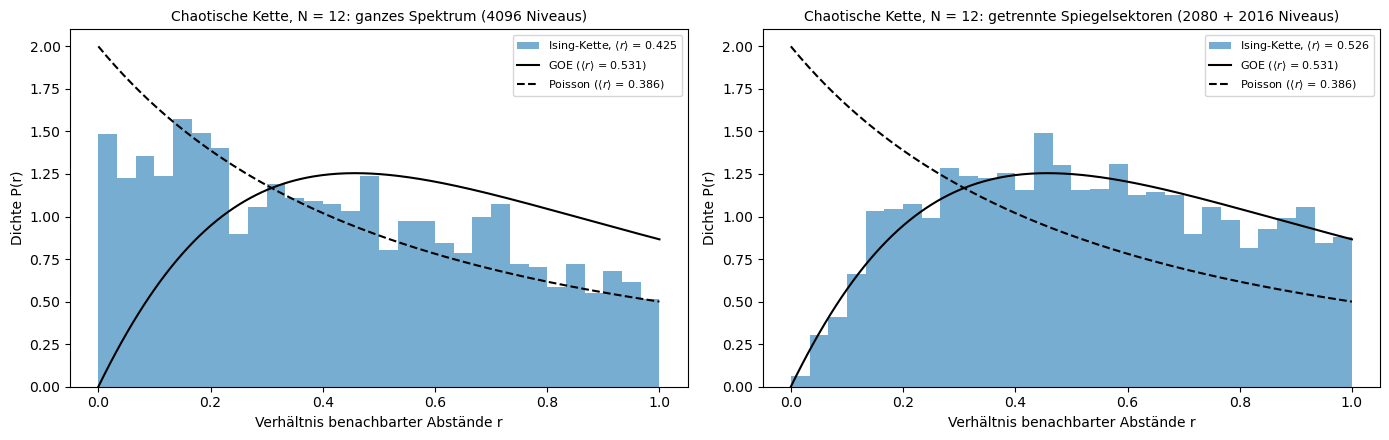

N = 12, h_z = 0.5  (5 s)
  ganzes Spektrum:         ⟨r⟩ = 0.425
  Spiegelsektor gerade:    ⟨r⟩ = 0.525   (2080 Niveaus)
  Spiegelsektor ungerade:  ⟨r⟩ = 0.528   (2016 Niveaus)
  Anteil r < 0.1: ganzes Spektrum 13.6%, Sektoren 2.6%


In [2]:
N1 = 12
t0 = time.time()
H1 = ising_sparse(N1, H_X, H_Z)
E_full = spectrum(H1)
E_even = spectrum(H1, sector_basis(N1, mirror=+1))
E_odd = spectrum(H1, sector_basis(N1, mirror=-1))
r_full, r_even, r_odd = gap_ratios(E_full), gap_ratios(E_even), gap_ratios(E_odd)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
rr = np.linspace(0, 1, 200)
for ax, r, title in [(axes[0], r_full, f"ganzes Spektrum ({len(E_full)} Niveaus)"),
                     (axes[1], np.r_[r_even, r_odd], f"getrennte Spiegelsektoren ({len(E_even)} + {len(E_odd)} Niveaus)")]:
    ax.hist(r, bins=np.linspace(0, 1, 31), density=True, color="tab:blue", alpha=0.6, label=rf"Ising-Kette, $\langle r\rangle$ = {r.mean():.3f}")
    ax.plot(rr, p_r_goe(rr), "k-", label=rf"GOE ($\langle r\rangle$ = {R_GOE:.3f})")
    ax.plot(rr, p_r_poisson(rr), "k--", label=rf"Poisson ($\langle r\rangle$ = {R_POISSON:.3f})")
    ax.set_xlabel("Verhältnis benachbarter Abstände r")
    ax.set_ylabel("Dichte P(r)")
    ax.set_title(f"Chaotische Kette, N = {N1}: {title}", fontsize=10)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"N = {N1}, h_z = {H_Z}  ({time.time() - t0:.0f} s)")
print(f"  ganzes Spektrum:         ⟨r⟩ = {r_full.mean():.3f}")
print(f"  Spiegelsektor gerade:    ⟨r⟩ = {r_even.mean():.3f}   ({len(E_even)} Niveaus)")
print(f"  Spiegelsektor ungerade:  ⟨r⟩ = {r_odd.mean():.3f}   ({len(E_odd)} Niveaus)")
print(f"  Anteil r < 0.1: ganzes Spektrum {np.mean(r_full < 0.1):.1%}, Sektoren {np.mean(np.r_[r_even, r_odd] < 0.1):.1%}")

* Das **linke Bild** zeigt die Verteilung von $r$ für das ganze Spektrum. Kleine Verhältnisse nahe 0 sind häufig, wie bei der Poisson-Kurve (gestrichelt): Oft liegen zwei Niveaus fast aufeinander, weil eines aus dem geraden und eines aus dem ungeraden Sektor stammt und die beiden sich nicht abstoßen. Für große $r$ liegt das Histogramm zwischen den beiden Kurven.
* Das **rechte Bild** zeigt dieselbe Kette mit getrennten Sektoren: Die Verteilung beginnt bei 0, steigt linear an und folgt der GOE-Kurve (durchgezogen). Die Niveaus innerhalb eines Sektors stoßen sich ab.
* Die **Ausgabe** gibt $\langle r\rangle = 0.425$ für das ganze Spektrum, nur wenig über Poisson, und $0.525$ und $0.528$ für die beiden Sektoren, knapp unter dem GOE-Wert 0.531 (die Abweichung ist ein Effekt der endlichen Kette). Verhältnisse unter 0.1 haben 13.6 % im ganzen Spektrum, aber nur 2.6 % in den Sektoren. Wer die Symmetrie übersieht, hält eine chaotische Kette also fast für integrabel.

##### *2. Chaotisch gegen integrabel: kurze und lange Abstände*

Unterscheiden sich die integrable ($h_z = 0$) und die chaotische Kette ($h_z = 0.5$) schon bei benachbarten Niveaus, und wie gleichmäßig sind ihre Niveaus über viele Abstände verteilt? Vorher vorhersagen: Wie stark schwankt die Zahl der Niveaus in einem Fenster, in dem im Mittel 32 Niveaus liegen, beim GOE und bei Poisson?

Für $N = 14$ wird die chaotische Kette im geraden Spiegelsektor diagonalisiert (8256 Zustände, etwa 20 s), die integrable im Sektor, der unter Spiegelung und Spin-Flip gerade ist (4160 Zustände). Beide Spektren werden entfaltet (Theorie, Abschnitt 1). Links steht die Verteilung der Abstände benachbarter Niveaus mit der Wigner-Vermutung und $e^{-s}$, rechts die Zahlenvarianz $\Sigma^2(L)$ für Fenster von 0.5 bis 32 mittleren Abständen mit den Vorhersagen für GOE und Poisson (Abschnitt 5).

**Hintergrund & Fachbegriffe:**
- **Entfaltete Abstände:** Abstände in Einheiten des lokalen mittleren Abstands, sodass ihr Mittelwert überall 1 ist.
- **Wigner-Vermutung:** $P(s) = \frac\pi2 s\,e^{-\pi s^2/4}$, die Abstandsverteilung des GOE in sehr guter Näherung.
- **Zahlenvarianz $\Sigma^2(L)$:** wie stark die Zahl der Niveaus in einem Fenster der Länge $L$ schwankt; ein Maß für Korrelationen über viele Abstände.
- **Starrheit (spectral rigidity):** ein Spektrum, dessen Niveaus so gleichmäßig liegen, dass die Zahl in einem langen Fenster kaum schwankt.

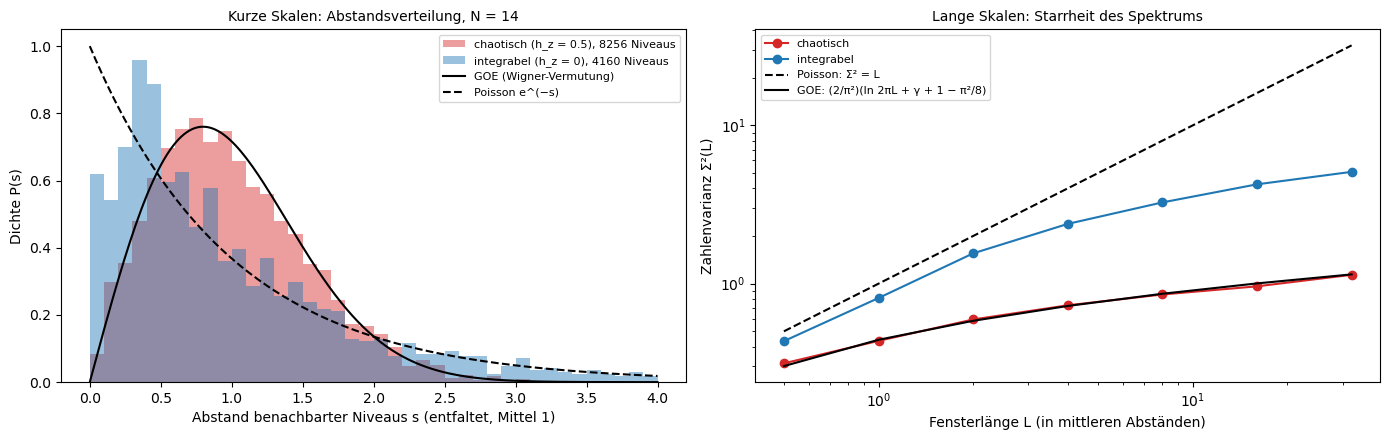

N = 14  (22 s)
  chaotisch : ⟨r⟩ = 0.528,  Anteil s < 0.1: 0.8% (GOE 0.8%, Poisson 9.5%),  Σ²(L = 1, 8, 32) = 0.44, 0.85, 1.14
  integrabel: ⟨r⟩ = 0.411,  Anteil s < 0.1: 6.1% (GOE 0.8%, Poisson 9.5%),  Σ²(L = 1, 8, 32) = 0.81, 3.26, 5.09
  GOE-Formel: Σ²(L = 1, 8, 32) = 0.44, 0.86, 1.14


In [3]:
N2 = 14
t0 = time.time()
E_chaos = spectrum(ising_sparse(N2, H_X, H_Z), sector_basis(N2, mirror=+1))
E_int = spectrum(ising_sparse(N2, H_X, 0.0), sector_basis(N2, mirror=+1, flip=+1))   # h_z = 0: auch Spin-Flip-Symmetrie
LS = np.array([0.5, 1, 2, 4, 8, 16, 32])
res = {}
for label, E in [("chaotisch", E_chaos), ("integrabel", E_int)]:
    e = middle(unfold(E))
    res[label] = dict(s=np.diff(e), sigma2=number_variance(e, LS), r=gap_ratios(E).mean(), n=len(E))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ss = np.linspace(0, 4, 200)
for label, c in [("chaotisch", "tab:red"), ("integrabel", "tab:blue")]:
    axes[0].hist(res[label]["s"], bins=np.linspace(0, 4, 41), density=True, alpha=0.45, color=c,
                 label=f"{label} (h_z = {H_Z if label == 'chaotisch' else 0}), {res[label]['n']} Niveaus")
    axes[1].plot(LS, res[label]["sigma2"], "o-", c=c, label=label)
axes[0].plot(ss, wigner_goe(ss), "k-", label="GOE (Wigner-Vermutung)")
axes[0].plot(ss, np.exp(-ss), "k--", label="Poisson e^(−s)")
axes[0].set_xlabel("Abstand benachbarter Niveaus s (entfaltet, Mittel 1)")
axes[0].set_ylabel("Dichte P(s)")
axes[0].set_title(f"Kurze Skalen: Abstandsverteilung, N = {N2}", fontsize=10)
axes[0].legend(fontsize=8)
axes[1].plot(LS, LS, "k--", label="Poisson: Σ² = L")
axes[1].plot(LS, sigma2_goe(LS), "k-", label="GOE: (2/π²)(ln 2πL + γ + 1 − π²/8)")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("Fensterlänge L (in mittleren Abständen)")
axes[1].set_ylabel("Zahlenvarianz Σ²(L)")
axes[1].set_title("Lange Skalen: Starrheit des Spektrums", fontsize=10)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"N = {N2}  ({time.time() - t0:.0f} s)")
for label in res:
    s = res[label]["s"]
    print(f"  {label:10s}: ⟨r⟩ = {res[label]['r']:.3f},  Anteil s < 0.1: {np.mean(s < 0.1):.1%} "
          f"(GOE {1 - np.exp(-np.pi * 0.01 / 4):.1%}, Poisson {1 - np.exp(-0.1):.1%}),  Σ²(L = 1, 8, 32) = "
          + ", ".join(f"{v:.2f}" for v in res[label]["sigma2"][[1, 4, 6]]))
print(f"  GOE-Formel: Σ²(L = 1, 8, 32) = " + ", ".join(f"{v:.2f}" for v in sigma2_goe(np.array([1, 8, 32]))))

* Das **linke Bild** zeigt die Abstandsverteilungen. Die chaotische Kette (rot) liegt auf der Wigner-Vermutung: fast keine Abstände nahe 0, ein Maximum bei etwa 0.8, kaum große Lücken. Die integrable Kette (blau) hat viele kleine Abstände und folgt ungefähr $e^{-s}$, mit Abweichungen: Das Maximum liegt bei 0.3 bis 0.5 statt bei 0, und große Abstände sind etwas häufiger.
* Das **rechte Bild** zeigt die Zahlenvarianz, doppelt logarithmisch. Die chaotische Kette liegt genau auf der GOE-Kurve (durchgezogen), die nur logarithmisch wächst. Die integrable Kette folgt bis $L \approx 2$ ungefähr der Poisson-Geraden $\Sigma^2 = L$, wächst danach aber immer langsamer: Auf langen Skalen ist ihr Spektrum steifer als unabhängige Niveaus. Das ist die Spur der freien Fermionen, deren $2^{14}$ Niveaus aus nur 14 Einteilchenenergien zusammengesetzt sind (Theorie, Abschnitt 7).
* Die **Ausgabe** gibt $\langle r\rangle = 0.528$ (chaotisch) und $0.411$ (integrabel). Abstände unter 0.1 haben 0.8 % der chaotischen Niveaus (GOE: 0.8 %) und 6.1 % der integrablen (Poisson: 9.5 %). Die Zahlenvarianz bei $L = 1, 8, 32$ ist $0.44, 0.85, 1.14$ für die chaotische Kette, gleich der GOE-Formel $0.44, 0.86, 1.14$; die integrable Kette hat $0.81, 3.26, 5.09$.

##### *3. Der Übergang von integrabel zu chaotisch*

Wie stark muss das Längsfeld $h_z$ sein, damit die Kette chaotisch wird, und hängt das von ihrer Länge ab? Vorher vorhersagen: Wird eine längere Kette bei kleinerem oder bei größerem $h_z$ chaotisch?

Für $N = 9$, 11 und 13 und 14 Werte von $h_z$ zwischen 0.01 und 6 (logarithmisch verteilt) wird $\langle r\rangle$ in beiden Spiegelsektoren berechnet und gemittelt (etwa 1.5 Minuten). Ungerade Längen haben zwei fast gleich große Sektoren. Bei $h_z = 0$ wäre die Kette integrabel (Theorie, Abschnitt 7); die gepunktete Linie markiert das $h_z = 0.5$ der anderen Experimente.

**Hintergrund & Fachbegriffe:**
- **Integrabilitätsbrechung:** eine Störung, die die vielen Erhaltungsgrößen eines integrablen Systems zerstört; hier das Längsfeld $h_z\sum Z_i$.
- **Endliche Größe (finite size):** Effekte, die nur in kleinen Systemen auftreten und mit wachsendem $N$ verschwinden oder sich verschieben; deshalb vergleicht man mehrere Längen.
- **Crossover:** ein stetiger Übergang zwischen zwei Verhaltensweisen ohne scharfe Grenze, die bei endlichem $N$ immer verschmiert ist.

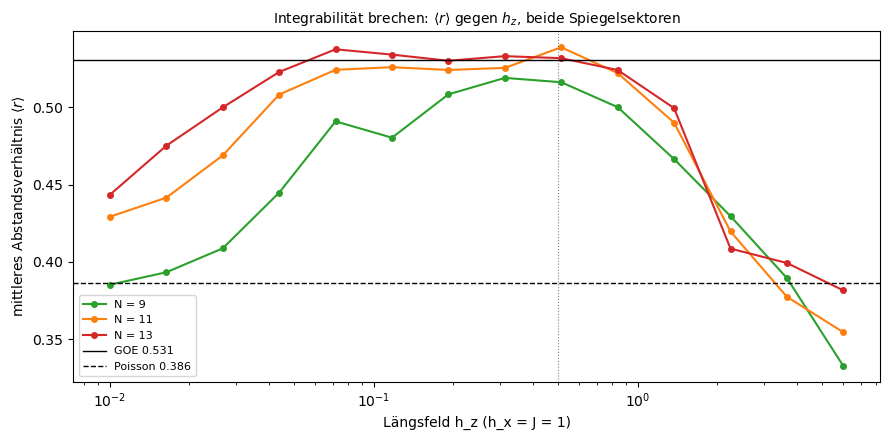

(69 s)
h_z:      0.010  0.016  0.027  0.044  0.072  0.117  0.192  0.313  0.512  0.838  1.371  2.243  3.668  6.000
N =  9:   0.385  0.393  0.409  0.445  0.491  0.480  0.508  0.519  0.516  0.500  0.466  0.430  0.390  0.333
N = 11:   0.429  0.442  0.469  0.508  0.524  0.526  0.524  0.525  0.539  0.522  0.490  0.420  0.377  0.355
N = 13:   0.443  0.475  0.500  0.523  0.537  0.534  0.530  0.533  0.532  0.524  0.499  0.409  0.399  0.382
N =  9: ⟨r⟩ > 0.5 für h_z von 0.192 bis 0.84
N = 11: ⟨r⟩ > 0.5 für h_z von 0.044 bis 0.84
N = 13: ⟨r⟩ > 0.5 für h_z von 0.044 bis 0.84


In [4]:
HZS = np.geomspace(0.01, 6, 14)
t0 = time.time()
r_sweep = {}
for n in [9, 11, 13]:
    Vs = [sector_basis(n, mirror=+1), sector_basis(n, mirror=-1)]
    r_sweep[n] = np.array([np.concatenate([gap_ratios(spectrum(ising_sparse(n, H_X, hz), V)) for V in Vs]).mean() for hz in HZS])

fig, ax = plt.subplots(figsize=(9, 4.5))
for n, c in zip(r_sweep, ["tab:green", "tab:orange", "tab:red"]):
    ax.plot(HZS, r_sweep[n], "o-", c=c, ms=4, label=f"N = {n}")
ax.axhline(R_GOE, color="black", lw=1, label="GOE 0.531")
ax.axhline(R_POISSON, color="black", lw=1, ls="--", label="Poisson 0.386")
ax.axvline(H_Z, color="grey", lw=0.8, ls=":")
ax.set_xscale("log")
ax.set_xlabel("Längsfeld h_z (h_x = J = 1)")
ax.set_ylabel(r"mittleres Abstandsverhältnis $\langle r\rangle$")
ax.set_title(r"Integrabilität brechen: $\langle r\rangle$ gegen $h_z$, beide Spiegelsektoren", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"({time.time() - t0:.0f} s)")
print("h_z:     " + " ".join(f"{h:6.3f}" for h in HZS))
for n in r_sweep:
    print(f"N = {n:2d}:  " + " ".join(f"{r:6.3f}" for r in r_sweep[n]))
for n in r_sweep:
    above = HZS[r_sweep[n] > 0.5]
    print(f"N = {n:2d}: ⟨r⟩ > 0.5 für h_z von {above.min():.3f} bis {above.max():.2f}")

* Das **Bild** zeigt $\langle r\rangle$ gegen $h_z$ auf logarithmischer Achse. Bei kleinem Feld liegen die Werte nahe Poisson, in der Mitte erreichen alle drei Längen ein Plateau am GOE-Wert, und bei großem Feld fallen sie wieder auf Poisson oder darunter. Das Plateau ist für $N = 13$ (rot) am breitesten und beginnt am weitesten links.
* Der **linke Rand** des Plateaus wandert mit wachsendem $N$ zu kleineren Feldern: Bei $h_z = 0.01$ ist $N = 9$ noch Poisson (0.385), $N = 13$ schon auf halbem Weg zum GOE (0.443). Das passt zu Theorie, Abschnitt 7: Der Niveauabstand schrumpft wie $2^{-N}$, also mischt eine kleinere Störung die Niveaus. Der **rechte Rand** liegt für alle drei Längen bei $h_z \approx 1$ bis 2; dort wird $J\sum Z_iZ_{i+1} + h_z\sum Z_i$ so groß, dass das Querfeld $h_x$ die Basiszustände kaum noch mischt.
* Die **Ausgabe** gibt die Tabelle der Werte und den Bereich mit $\langle r\rangle > 0.5$: für $N = 9$ von $h_z = 0.19$ bis 0.84, für $N = 11$ und $N = 13$ von 0.044 bis 0.84 (bei $N = 13$ ist schon $h_z = 0.027$ mit 0.500 an der Grenze). Werte unter 0.386 bei sehr großem Feld kommen von fast entarteten Niveaus der nahezu klassischen Kette.

##### *4. Der spektrale Formfaktor: Abfall, Rampe, Plateau*

Sieht man die Niveauabstoßung auch als Funktion der Zeit, und wann hört die Zeitentwicklung auf, neue Information über das Spektrum zu liefern? Vorher vorhersagen: Bei welcher Zeit $\tau$ erreicht der Formfaktor das Plateau, und welche Form hat er davor für unkorrelierte Niveaus?

Für $N = 10$ werden je 200 Ketten mit schwacher Unordnung diagonalisiert: chaotisch mit $h_{x,i} = 1 \pm 0.2$ und $h_{z,i} = 0.5 \pm 0.2$ (gleichverteilt, an jedem Platz anders), integrabel mit $h_{x,i} = 1 \pm 0.2$ und $h_z = 0$ im Spin-Flip-Sektor. Die Unordnung bricht die Spiegelsymmetrie und liefert das Ensemble, über das der Formfaktor gemittelt werden muss (Theorie, Abschnitt 6). Links steht der volle Formfaktor $K(\tau)$, rechts der verbundene Teil $K_c(\tau)$ mit der GOE-Formel; beide sind über 9 benachbarte Zeitpunkte geglättet.

**Hintergrund & Fachbegriffe:**
- **Heisenberg-Zeit $t_H$:** $2\pi\hbar$ geteilt durch den mittleren Niveauabstand; die Zeit, nach der die Dynamik einzelne Niveaus auflöst. In einer Kette mit $N$ Qubits wächst sie wie $2^N$.
- **Ensemblemittel:** der Mittelwert über viele ähnliche, zufällig gestörte Systeme; er ersetzt beim Formfaktor das fehlende Selbstmitteln.
- **Verbundener Formfaktor $K_c$:** der Formfaktor ohne den Beitrag der mittleren Dichte, nur aus den Korrelationen der Niveaus.
- **Abfall, Rampe, Plateau (dip, ramp, plateau):** die typische Form von $K(\tau)$ eines chaotischen Systems auf doppelt logarithmischen Achsen.

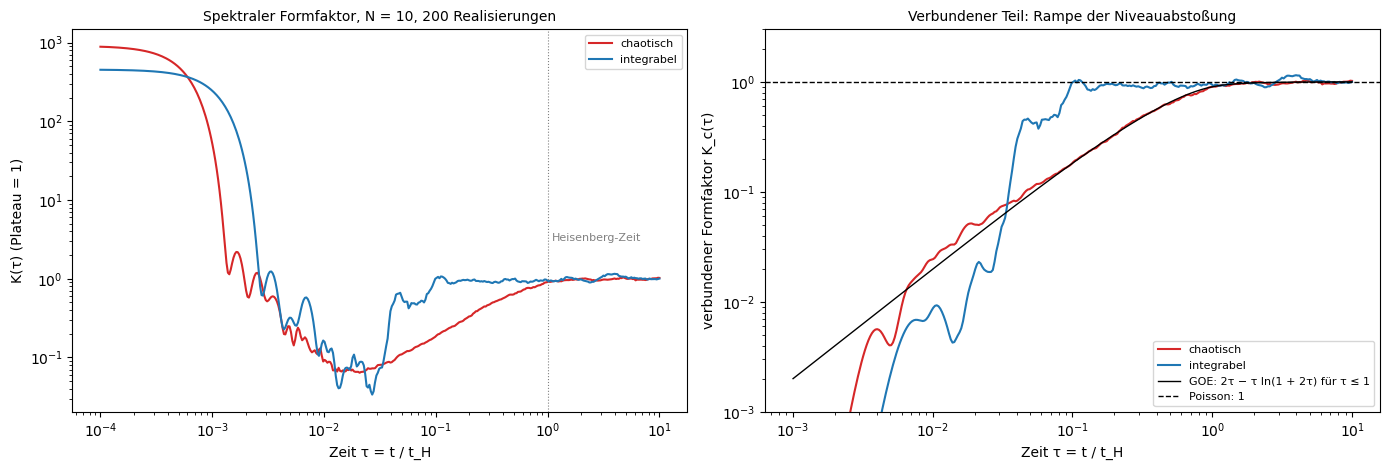

N = 10, 200 Realisierungen mit Unordnung ±0.2  (19 s)
  ⟨r⟩ chaotisch 0.530,  integrabel 0.393
  Abfall: K(τ = 1e-4) = 886, tiefster Punkt K = 0.064 bei τ = 0.0208
  τ =  0.01:  K_c chaotisch 0.025  (GOE 0.020),  integrabel 0.009
  τ =  0.10:  K_c chaotisch 0.180  (GOE 0.182),  integrabel 0.976
  τ =  0.30:  K_c chaotisch 0.461  (GOE 0.459),  integrabel 0.911
  τ =  1.00:  K_c chaotisch 0.899  (GOE 0.901),  integrabel 0.946
  τ =  3.00:  K_c chaotisch 0.946  (GOE 0.991),  integrabel 1.030


In [5]:
N4, REALIZATIONS, W = 10, 200, 0.2
taus = np.geomspace(1e-4, 10, 400)
rng = np.random.default_rng(5)
t0 = time.time()
# Unordnung in den Feldern bricht die Spiegelsymmetrie; die Kette bleibt reell (GOE)
chaos = [spectrum(ising_sparse(N4, H_X + W * rng.uniform(-1, 1, N4), H_Z + W * rng.uniform(-1, 1, N4)))
         for _ in range(REALIZATIONS)]
V_flip = sector_basis(N4, mirror=None, flip=+1)                         # h_z = 0: freie Fermionen, Spin-Flip-Sektor
integ = [spectrum(ising_sparse(N4, H_X + W * rng.uniform(-1, 1, N4), 0.0), V_flip) for _ in range(REALIZATIONS)]
K_chaos, Kc_chaos = form_factor(chaos, taus)
K_int, Kc_int = form_factor(integ, taus)
smooth = lambda y: uniform_filter1d(y, 9, mode="nearest")             # gleitendes Mittel gegen das Zittern

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].loglog(taus, smooth(K_chaos), c="tab:red", label="chaotisch")
axes[0].loglog(taus, smooth(K_int), c="tab:blue", label="integrabel")
axes[0].axvline(1, color="grey", ls=":", lw=0.8)
axes[0].text(1.1, 3, "Heisenberg-Zeit", color="grey", fontsize=8)
axes[0].set_xlabel("Zeit τ = t / t_H")
axes[0].set_ylabel("K(τ) (Plateau = 1)")
axes[0].set_title(f"Spektraler Formfaktor, N = {N4}, {REALIZATIONS} Realisierungen", fontsize=10)
axes[0].legend(fontsize=8)
mask = taus > 1e-3
axes[1].loglog(taus[mask], smooth(Kc_chaos)[mask], c="tab:red", label="chaotisch")
axes[1].loglog(taus[mask], smooth(Kc_int)[mask], c="tab:blue", label="integrabel")
axes[1].loglog(taus[mask], b_goe(taus[mask]), "k-", lw=1, label="GOE: 2τ − τ ln(1 + 2τ) für τ ≤ 1")
axes[1].axhline(1, color="black", ls="--", lw=1, label="Poisson: 1")
axes[1].set_ylim(1e-3, 3)
axes[1].set_xlabel("Zeit τ = t / t_H")
axes[1].set_ylabel("verbundener Formfaktor K_c(τ)")
axes[1].set_title("Verbundener Teil: Rampe der Niveauabstoßung", fontsize=10)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"N = {N4}, {REALIZATIONS} Realisierungen mit Unordnung ±{W}  ({time.time() - t0:.0f} s)")
print(f"  ⟨r⟩ chaotisch {np.mean([gap_ratios(E).mean() for E in chaos]):.3f},  integrabel {np.mean([gap_ratios(E).mean() for E in integ]):.3f}")
k_dip = np.argmin(smooth(K_chaos))
print(f"  Abfall: K(τ = 1e-4) = {K_chaos[0]:.0f}, tiefster Punkt K = {smooth(K_chaos)[k_dip]:.3f} bei τ = {taus[k_dip]:.4f}")
for t in [0.01, 0.1, 0.3, 1, 3]:
    k = np.argmin(np.abs(taus - t))
    print(f"  τ = {t:5.2f}:  K_c chaotisch {smooth(Kc_chaos)[k]:.3f}  (GOE {b_goe(t):.3f}),  integrabel {smooth(Kc_int)[k]:.3f}")

* Das **linke Bild** zeigt den vollen Formfaktor. Bei kleinen $\tau$ ist er groß (886 bei $\tau = 10^{-4}$) und fällt schnell ab, weil sich die Phasen der Niveaus über die ganze Breite des Spektrums aufheben. Bei der chaotischen Kette (rot) folgt ein Minimum, der **Abfall** (dip), bei $\tau \approx 0.02$, dann steigt $K$ entlang einer **Rampe** an und erreicht bei der Heisenberg-Zeit $\tau = 1$ das **Plateau** 1. Die integrable Kette (blau) steigt zwischen $\tau \approx 0.03$ und $0.1$ steil direkt auf das Plateau: Es gibt keine Rampe.
* Das **rechte Bild** zeigt den verbundenen Teil. Die chaotische Kette liegt von $\tau \approx 0.03$ bis zum Plateau auf der GOE-Kurve $2\tau - \tau\ln(1 + 2\tau)$. Bei kleineren $\tau$ weicht sie ab, erst etwas nach oben, unterhalb von $0.007$ weit nach unten: Kleine $\tau$ entsprechen Korrelationen über viele Niveaus, und dort wirken Filter, Entfalten und die kleine Kette. Die integrable Kette ist ab $\tau \approx 0.1$ flach bei 1, wie für unkorrelierte Niveaus. Darunter fällt sie steil ab: Das ist die Starrheit auf langen Skalen aus Experiment 2, denn kleine $\tau$ entsprechen vielen Abständen ($1/\tau$ Niveaus).
* Die **Ausgabe** gibt $\langle r\rangle = 0.530$ (chaotisch mit Unordnung) und $0.393$ (integrabel) und $K_c$ an fünf Zeiten: chaotisch $0.180$, $0.461$, $0.899$ bei $\tau = 0.1$, $0.3$, $1$ gegen die GOE-Werte $0.182$, $0.459$, $0.901$. Die Rampe ist die Niveauabstoßung, gesehen als Funktion der Zeit.

#### **Ergebnis**

Beim Lauf vom 2026-10-24:

- **Symmetrien (Experiment 1):** Die chaotische Kette ($N = 12$, $h_z = 0.5$) gibt ohne Trennung der Spiegelsektoren $\langle r\rangle = 0.425$, nahe an Poisson (0.386); in den Sektoren $0.525$ und $0.528$, nahe am GOE (0.531). Verhältnisse unter 0.1 fallen von 13.6 % auf 2.6 %.
- **Kurze und lange Abstände (Experiment 2):** Bei $N = 14$ folgt die chaotische Kette der Wigner-Vermutung (0.8 % Abstände unter 0.1, wie beim GOE) und der GOE-Zahlenvarianz auf 0.01 genau ($\Sigma^2 = 0.44, 0.85, 1.14$ bei $L = 1, 8, 32$). Die integrable Kette hat viele kleine Abstände (6.1 %, $\langle r\rangle = 0.411$), ist aber auf langen Skalen steifer als Poisson ($\Sigma^2(32) = 5.1$ statt 32), weil ihre Niveaus aus nur 14 Einteilchenenergien zusammengesetzt sind.
- **Übergang (Experiment 3):** $\langle r\rangle > 0.5$ gilt für $N = 9$ ab $h_z = 0.19$, für $N = 11$ und 13 schon ab $0.044$; bei $h_z = 0.01$ ist $N = 9$ noch Poisson (0.385), $N = 13$ schon bei 0.443. Oberhalb von $h_z \approx 1$ bis 2 wird die Kette für alle Längen wieder fast integrabel.
- **Formfaktor (Experiment 4):** Die chaotischen Ketten mit Unordnung ($N = 10$, 200 Realisierungen) zeigen Abfall, Rampe und Plateau; der verbundene Formfaktor liegt von $\tau \approx 0.03$ bis zur Heisenberg-Zeit auf der GOE-Kurve ($0.180$, $0.461$, $0.899$ bei $\tau = 0.1$, $0.3$, $1$ gegen $0.182$, $0.459$, $0.901$). Die integrablen Ketten haben keine Rampe und erreichen das Plateau schon bei $\tau \approx 0.1$.

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code ändern und prüfen:

1. **Symmetrie vergessen:** In Experiment 2 die chaotische Kette mit `sector_basis(N2, mirror=None)` statt `mirror=+1`, also ohne Trennung, auswerten (dauert wegen der $16384\times16384$-Matrix einige Minuten; mit `N2 = 12` geht es schnell). *(Vorhersage: $\langle r\rangle$ fällt auf etwa 0.43 wie in Experiment 1, und die Zahlenvarianz wächst schneller als beim GOE; bei $N = 12$ ist $\Sigma^2(32) \approx 2.3$ statt 1.1.)*
2. **Nur eine von zwei Symmetrien:** Die integrable Kette in Experiment 2 nur nach der Spiegelung trennen, `sector_basis(N2, mirror=+1)`. *(Vorhersage: kaum ein Unterschied, $\langle r\rangle$ bleibt nahe Poisson; zwei übereinandergelegte Poisson-Spektren sind wieder Poisson.)*
3. **Weniger Realisierungen:** In Experiment 4 `REALIZATIONS = 10`. *(Vorhersage: Die Rampe wird zittrig, und einzelne Werte weichen um 10 bis 40 % von der GOE-Kurve ab; der Formfaktor mittelt sich nicht selbst.)*
4. **Ein anderer chaotischer Punkt:** In Experiment 1 `H_X = 1.05` wie bei Kim und Huse (2013). *(Vorhersage: dieselben Werte im Rahmen der Schwankung, etwa ±0.02: Die Statistik ist universell.)*
5. **Kürzere Kette:** In Experiment 1 `N1 = 8`. *(Vorhersage: Die Sektoren haben nur 136 und 120 Niveaus, von denen gut 100 ausgewertet werden; $\langle r\rangle$ liegt im Mittel noch nahe am GOE, schwankt aber um etwa ±0.05 zwischen den Sektoren.)*

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Was sagt die Bohigas-Giannoni-Schmit-Vermutung, und was ist das Gegenstück für integrable Systeme?</summary>

Chaotische Quantensysteme haben die Niveaustatistik des passenden Zufallsmatrix-Ensembles (GOE mit, GUE ohne Zeitumkehrsymmetrie). Generische integrable Systeme haben nach Berry und Tabor Poisson-Statistik, also unkorrelierte Niveaus.
</details>

<details><summary>2. Warum stoßen sich die Niveaus eines chaotischen Systems ab?</summary>

Damit zwei Niveaus zusammenfallen, müssen mehrere unabhängige Matrixelemente zugleich verschwinden (beim GOE zwei Bedingungen für die $2\times2$-Matrix). Das ist unwahrscheinlich, deshalb geht $P(s)$ für kleine $s$ wie $s^\beta$ gegen null, beim GOE linear.
</details>

<details><summary>3. Warum muss man das Spektrum nach Symmetrien trennen?</summary>

Niveaus aus verschiedenen Symmetriesektoren stoßen sich nicht ab. Übereinandergelegt sehen die Spektren unkorreliert aus: Die chaotische Kette gibt ohne Trennung $\langle r\rangle = 0.43$ statt $0.53$, fast wie eine integrable.
</details>

<details><summary>4. Welche Symmetrien hat die Ising-Kette, und wann gibt es den Spin-Flip?</summary>

Die Spiegelung $i \to N-1-i$ bei offenen Enden und gleichen Feldern, und den Spin-Flip $\prod_i X_i$ nur bei $h_z = 0$, weil er $Z_i$ das Vorzeichen umdreht. Unordnung in den Feldern zerstört die Spiegelung.
</details>

<details><summary>5. Was heißt Entfalten, und warum braucht das Abstandsverhältnis r keines?</summary>

Entfalten ersetzt jedes Niveau durch die glatte Zahl der Niveaus darunter, sodass der mittlere Abstand überall 1 ist. Im Verhältnis zweier benachbarter Abstände kürzt sich die lokale Dichte heraus.
</details>

<details><summary>6. Welche Werte hat das mittlere Abstandsverhältnis?</summary>

$2\ln2 - 1 \approx 0.386$ für Poisson, $\approx 0.531$ für GOE, $\approx 0.600$ für GUE. Die Ising-Kette gibt 0.53 (chaotisch, im Sektor) und 0.39 bis 0.41 (integrabel).
</details>

<details><summary>7. Was misst die Zahlenvarianz, und was zeigt sie für GOE und Poisson?</summary>

Wie stark die Zahl der Niveaus in einem Fenster der Länge $L$ schwankt. Poisson: $\Sigma^2 = L$. GOE: nur logarithmisches Wachstum, das Spektrum ist starr; bei $L = 32$ etwa 1.1 statt 32.
</details>

<details><summary>8. Warum ist die integrable Ising-Kette auf langen Skalen steifer als Poisson?</summary>

Sie besteht aus freien Fermionen: Jedes ihrer $2^N$ Niveaus ist eine Summe aus nur $N$ Einteilchenenergien. Die Niveaus sind deshalb nicht unabhängig, und die Zahlenvarianz wächst langsamer als $L$. Freie Fermionen sind kein generisches integrables System.
</details>

<details><summary>9. Warum wird eine längere Kette schon bei kleinerem Längsfeld chaotisch?</summary>

Eine Störung mischt zwei Niveaus, sobald ihr Matrixelement größer als ihr Abstand ist. Der Abstand schrumpft wie $2^{-N}$, weil die Zahl der Niveaus exponentiell wächst und die Breite des Spektrums nur linear. In Experiment 3 sinkt die Schwelle von $h_z \approx 0.19$ ($N = 9$) auf etwa 0.04 ($N = 11$ und 13).
</details>

<details><summary>10. Warum ist die Kette bei sehr großem Längsfeld wieder fast integrabel?</summary>

Dann dominiert der diagonale Teil $J\sum Z_iZ_{i+1} + h_z\sum Z_i$, und das Querfeld mischt die Basiszustände kaum noch. Die Eigenzustände sind fast klassische Konfigurationen mit fast unkorrelierten Energien.
</details>

<details><summary>11. Was sind Abfall, Rampe und Plateau des Formfaktors, und woher kommt die Rampe?</summary>

Der Abfall kommt von der mittleren Dichte: Die Phasen aller Niveaus heben sich auf. Die Rampe, $K_c \approx 2\tau - \tau\ln(1 + 2\tau)$ beim GOE, ist die Niveauabstoßung als Funktion der Zeit. Das Plateau ab der Heisenberg-Zeit entsteht, weil sich dann alle Terme mit verschiedenen Niveaus aufheben. Unkorrelierte Niveaus haben keine Rampe.
</details>

<details><summary>12. Warum braucht der Formfaktor ein Ensemble?</summary>

Er ist nicht selbstmittelnd: Für einen einzelnen Hamiltonoperator schwankt $\vert Z(\tau)\vert^2$ an jeder Stelle um 100 %. Erst der Mittelwert über viele Realisierungen, hier 200 Ketten mit schwacher Unordnung, zeigt die glatte Rampe.
</details>

<details><summary>13. Was ist die Heisenberg-Zeit, und wie hängt sie von der Kettenlänge ab?</summary>

$t_H = 2\pi\hbar/\Delta$ mit dem mittleren Niveauabstand $\Delta$: die Zeit, nach der die Dynamik einzelne Niveaus auflöst. Weil $\Delta$ ungefähr wie $2^{-N}$ schrumpft, wächst $t_H$ ungefähr wie $2^N$, weit länger als die Zeit, in der sich ein OTOC ausbreitet.
</details>

<details><summary>14. Warum gilt für die Ising-Kette das GOE und nicht das GUE?</summary>

Alle Matrixelemente sind reell: Die Kette hat eine antiunitäre Symmetrie (komplexe Konjugation) mit $T^2 = 1$. Erst Terme mit komplexen Matrixelementen, die sich durch keine Basiswahl reell machen lassen, führen zum GUE.
</details>

#### **Nächste Schritte**

- **Eigenzustände:** Wie sehen die Matrixelemente lokaler Observablen in der Eigenbasis aus (Hypothese der Eigenzustands-Thermalisierung)? Das ist das nächste Notebook der Serie, `chaos_eth`.
- **Lokalisierung:** Mit starker Unordnung wird eine wechselwirkende Kette wieder Poisson-artig (Vielteilchenlokalisierung); eine erste Version steht in [Zufallsmatrizen](https://github.com/deltorobarba/science/blob/main/maths/randommatrices.ipynb), Experiment 5, ausführlich später in `chaos_mbl`.
- **Thouless-Zeit:** die Zeit, ab der $K_c$ der GOE-Rampe folgt; wie sie mit der Kettenlänge wächst, sagt, wie schnell sich ein System als Ganzes chaotisch verhält.
- **Größere Ketten:** Mit Shift-Invert-Verfahren berechnet man nur einige hundert Niveaus in der Mitte des Spektrums und kommt bis etwa 20 Qubits.
- **GUE:** eine Kette mit gebrochener Zeitumkehr, etwa mit XY-Kopplung, Dzyaloshinskii-Moriya-Term und zufälligen Feldern; $\langle r\rangle$ sollte auf 0.60 steigen.
- **Eigenvektoren:** Die Amplituden chaotischer Eigenzustände in einer festen Basis sind Gauß-verteilt (Porter-Thomas-Verteilung ihrer Quadrate), dieselbe Verteilung wie bei Random Circuit Sampling.

#### **Referenzen**

- Wigner, E. P. (1955): *Characteristic vectors of bordered matrices with infinite dimensions*, Ann. Math. 62, 548.
- Dyson, F. J. (1962): *Statistical theory of the energy levels of complex systems. I*, J. Math. Phys. 3, 140.
- Pfeuty, P. (1970): *The one-dimensional Ising model with a transverse field*, Ann. Phys. 57, 79.
- Berry, M. V. & Tabor, M. (1977): *Level clustering in the regular spectrum*, Proc. R. Soc. Lond. A 356, 375.
- Brody, T. A. et al. (1981): *Random-matrix physics: spectrum and strength fluctuations*, Rev. Mod. Phys. 53, 385 (Zahlenvarianz und Starrheit).
- Bohigas, O., Giannoni, M. J. & Schmit, C. (1984): *Characterization of chaotic quantum spectra and universality of level fluctuation laws*, Phys. Rev. Lett. 52, 1.
- Mehta, M. L. (2004): *Random Matrices*, 3. Auflage, Elsevier.
- Oganesyan, V. & Huse, D. A. (2007): *Localization of interacting fermions at high temperature*, Phys. Rev. B 75, 155111 (Abstandsverhältnis $r$).
- Haake, F. (2010): *Quantum Signatures of Chaos*, 3. Auflage, Springer (Formfaktor, Abschnitt über Zufallsmatrizen).
- Atas, Y. Y., Bogomolny, E., Giraud, O. & Roux, G. (2013): *Distribution of the ratio of consecutive level spacings in random matrix ensembles*, Phys. Rev. Lett. 110, 084101.
- Kim, H. & Huse, D. A. (2013): *Ballistic spreading of entanglement in a diffusive nonintegrable system*, Phys. Rev. Lett. 111, 127205.
- D'Alessio, L., Kafri, Y., Polkovnikov, A. & Rigol, M. (2016): *From quantum chaos and eigenstate thermalization to statistical mechanics and thermodynamics*, Adv. Phys. 65, 239 (Abschnitt 2 und 3).
- Cotler, J. S. et al. (2017): *Black holes and random matrices*, JHEP 05, 118.
- Roushan, P. et al. (2017): *Spectroscopic signatures of localization with interacting photons in superconducting qubits*, Science 358, 1175.